# Chapter 6 Capstone — Dynamic Option Pricing Bake-Off

## Financial Question

How closely do different dynamic option-pricing methods agree when valuing European and American puts, and how do their accuracy, runtime, and early-exercise diagnostics compare?

This notebook compares:

1. Cox–Ross–Rubinstein (CRR) binomial pricing;
2. Monte Carlo pricing for a European put;
3. Least-Squares Monte Carlo (LSM) pricing for an American put.

The analysis focuses on both valuation and numerical diagnostics.

The baseline contract parameters are

$$
S_0=36,
\qquad
K=40,
\qquad
r=6\%,
\qquad
\sigma=20\%,
\qquad
T=1.
$$

The notebook will examine:

- convergence of CRR European prices toward Black–Scholes;
- CRR pricing of an American put by backward induction;
- Monte Carlo pricing uncertainty through standard errors;
- LSM estimation of continuation values;
- the estimated American early-exercise region;
- agreement between CRR and LSM;
- runtime and accuracy trade-offs across several numerical configurations.

The central Chapter 6 question is therefore

$$
\boxed{
\text{dynamic pricing method}
\rightarrow
\text{option value}
\rightarrow
\text{numerical error}
\rightarrow
\text{runtime}
\rightarrow
\text{exercise behavior}
}
$$

In [1]:
import math
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from numpy.random import default_rng
from scipy.stats import norm

S0 = 36.0
K = 40.0
r = 0.06
sigma = 0.20
T = 1.0

seed = 100

print("S0:", S0)
print("K:", K)
print("r:", r)
print("sigma:", sigma)
print("T:", T)
print("seed:", seed)

S0: 36.0
K: 40.0
r: 0.06
sigma: 0.2
T: 1.0
seed: 100


## 3. Baseline CRR Binomial Pricing

The Cox–Ross–Rubinstein model divides the maturity interval into

$$
m=500
$$

time steps of length

$$
\Delta t=\frac{T}{m}.
$$

The CRR parameters are

$$
u=e^{\sigma\sqrt{\Delta t}},
$$

$$
d=\frac{1}{u},
$$

$$
df=e^{-r\Delta t},
$$

and

$$
q=
\frac{e^{r\Delta t}-d}{u-d}.
$$

At maturity, a node reached after $j$ down moves has stock price

$$
S_T(j)
=
S_0u^{m-j}d^j,
\qquad
j=0,\ldots,m.
$$

The terminal put payoff is

$$
h_T(j)=\max(K-S_T(j),0).
$$

For the European put, backward induction applies

$$
V_t
=
df
\left[
qV_{t+\Delta t}^{up}
+
(1-q)V_{t+\Delta t}^{down}
\right].
$$

For the American put, every node additionally compares continuation with immediate exercise:

$$
V_t^{Am}
=
\max
\left(
K-S_t,
\;
df
\left[
qV_{t+\Delta t}^{up}
+
(1-q)V_{t+\Delta t}^{down}
\right]
\right).
$$

The American value can therefore exceed the European value because the holder has the additional right to exercise before maturity.

In [2]:
m_crr = 500

dt_crr = T / m_crr
df_crr = math.exp(-r * dt_crr)

u_crr = math.exp(
    sigma * math.sqrt(dt_crr)
)

d_crr = 1.0 / u_crr

q_crr = (
    math.exp(r * dt_crr) - d_crr
) / (
    u_crr - d_crr
)

# Terminal stock prices:
# j counts the number of down moves.
j = np.arange(m_crr + 1)

ST_crr = (
    S0
    * u_crr ** (m_crr - j)
    * d_crr ** j
)

terminal_put = np.maximum(
    K - ST_crr,
    0.0,
)

# European put: discounted risk-neutral backward induction
V_eur = terminal_put.copy()

for step in range(
    m_crr,
    0,
    -1,
):
    V_eur = df_crr * (
        q_crr * V_eur[:-1]
        + (1.0 - q_crr) * V_eur[1:]
    )

crr_european = float(
    V_eur[0]
)

# American put: backward induction plus early-exercise test
V_am = terminal_put.copy()

for step in range(
    m_crr,
    0,
    -1,
):
    continuation = df_crr * (
        q_crr * V_am[:-1]
        + (1.0 - q_crr) * V_am[1:]
    )

    j = np.arange(step)

    S_t = (
        S0
        * u_crr ** ((step - 1) - j)
        * d_crr ** j
    )

    intrinsic = np.maximum(
        K - S_t,
        0.0,
    )

    V_am = np.maximum(
        intrinsic,
        continuation,
    )

crr_american = float(
    V_am[0]
)

early_exercise_premium = (
    crr_american
    - crr_european
)

print("CRR steps:", m_crr)
print("dt:", dt_crr)
print("q:", q_crr)
print("European put (CRR):", crr_european)
print("American put (CRR):", crr_american)
print("Early-exercise premium:", early_exercise_premium)

CRR steps: 500
dt: 0.002
q: 0.5044724639230862
European put (CRR): 3.8435911863372136
American put (CRR): 4.48637477750599
Early-exercise premium: 0.6427835911687763


## 4. Analytical Benchmark for the European Put

The CRR European price can be compared with the analytical Black–Scholes value.

For a European put,

$$
P_0
=
Ke^{-rT}N(-d_2)
-
S_0N(-d_1),
$$

where

$$
d_1
=
\frac{
\ln(S_0/K)
+
(r+\tfrac12\sigma^2)T
}{
\sigma\sqrt T
},
$$

and

$$
d_2=d_1-\sigma\sqrt T.
$$

The absolute CRR pricing error is

$$
\left|
P_0^{CRR}
-
P_0^{BS}
\right|.
$$

This comparison measures numerical discretization error in the finite-step CRR approximation.

In [3]:
d1 = (
    math.log(S0 / K)
    + (r + 0.5 * sigma ** 2) * T
) / (
    sigma * math.sqrt(T)
)

d2 = (
    d1
    - sigma * math.sqrt(T)
)

bs_european = (
    K
    * math.exp(-r * T)
    * norm.cdf(-d2)
    - S0 * norm.cdf(-d1)
)

crr_abs_error = abs(
    crr_european
    - bs_european
)

crr_rel_error = (
    crr_abs_error
    / bs_european
)

print("d1:", d1)
print("d2:", d2)
print("European put (BS):", bs_european)
print("European put (CRR):", crr_european)
print("Absolute CRR error:", crr_abs_error)
print("Relative CRR error:", crr_rel_error)

d1: -0.12680257828913138
d2: -0.3268025782891314
European put (BS): 3.84430779159684
European put (CRR): 3.8435911863372136
Absolute CRR error: 0.0007166052596265793
Relative CRR error: 0.00018640683797301188


## 5. Reusable CRR Pricing Engine

The direct CRR calculation can now be packaged into a reusable pricing function.

The function takes the contract parameters and number of tree steps as inputs and returns:

- the CRR time step;
- up and down factors;
- the one-step discount factor;
- the risk-neutral probability;
- the European put value;
- the American put value;
- the early-exercise premium;
- the total runtime.

The European and American calculations use the same CRR terminal stock-price grid.

The American calculation differs only by adding the nodewise early-exercise rule

$$
V_t^{Am}
=
\max
\left(
h_t,
C_t
\right).
$$

Timing is measured with `time.perf_counter()` so that the same function can later be used in the capstone runtime leaderboard.

In [4]:
def crr_put_pricer(
    S0,
    K,
    r,
    sigma,
    T,
    m,
):
    """Price European and American puts with a CRR tree."""

    t0 = time.perf_counter()

    dt = T / m

    df = math.exp(
        -r * dt
    )

    u = math.exp(
        sigma * math.sqrt(dt)
    )

    d = 1.0 / u

    q = (
        math.exp(r * dt) - d
    ) / (
        u - d
    )

    # Terminal stock prices
    j = np.arange(m + 1)

    ST = (
        S0
        * u ** (m - j)
        * d ** j
    )

    terminal_put = np.maximum(
        K - ST,
        0.0,
    )

    # European put
    V_eur = terminal_put.copy()

    for step in range(
        m,
        0,
        -1,
    ):
        V_eur = df * (
            q * V_eur[:-1]
            + (1.0 - q) * V_eur[1:]
        )

    european = float(
        V_eur[0]
    )

    # American put
    V_am = terminal_put.copy()

    for step in range(
        m,
        0,
        -1,
    ):
        continuation = df * (
            q * V_am[:-1]
            + (1.0 - q) * V_am[1:]
        )

        j = np.arange(step)

        S_t = (
            S0
            * u ** ((step - 1) - j)
            * d ** j
        )

        intrinsic = np.maximum(
            K - S_t,
            0.0,
        )

        V_am = np.maximum(
            intrinsic,
            continuation,
        )

    american = float(
        V_am[0]
    )

    runtime = (
        time.perf_counter()
        - t0
    )

    return {
        "dt": dt,
        "df": df,
        "u": u,
        "d": d,
        "q": q,
        "european": european,
        "american": american,
        "early_exercise_premium": (
            american - european
        ),
        "runtime": runtime,
    }

In [5]:
baseline_crr = crr_put_pricer(
    S0=S0,
    K=K,
    r=r,
    sigma=sigma,
    T=T,
    m=m_crr,
)

print(
    "Function European:",
    baseline_crr["european"],
)

print(
    "Direct European:",
    crr_european,
)

print(
    "European matches:",
    np.isclose(
        baseline_crr["european"],
        crr_european,
    ),
)

print(
    "Function American:",
    baseline_crr["american"],
)

print(
    "Direct American:",
    crr_american,
)

print(
    "American matches:",
    np.isclose(
        baseline_crr["american"],
        crr_american,
    ),
)

print(
    "q matches:",
    np.isclose(
        baseline_crr["q"],
        q_crr,
    ),
)

print(
    "Runtime (s):",
    baseline_crr["runtime"],
)

Function European: 3.8435911863372136
Direct European: 3.8435911863372136
European matches: True
Function American: 4.48637477750599
Direct American: 4.48637477750599
American matches: True
q matches: True
Runtime (s): 0.035497486000167555


## 6. CRR Convergence Diagnostic

The finite-step CRR model approximates the continuous-time Black–Scholes model.

As the number of binomial steps increases,

$$
m\uparrow,
$$

the time interval

$$
\Delta t=\frac{T}{m}
$$

shrinks.

The European CRR put price should therefore converge toward the analytical Black–Scholes value.

For each tree size, the analysis records

$$
\text{absolute error}
=
\left|
P_0^{CRR}-P_0^{BS}
\right|,
$$

and

$$
\text{relative error}
=
\frac{
\left|
P_0^{CRR}-P_0^{BS}
\right|
}{
P_0^{BS}
}.
$$

The convergence may oscillate around the Black–Scholes benchmark rather than improve monotonically at every increase in $m$.

In [6]:
m_grid = np.array(
    [
        5,
        10,
        25,
        50,
        100,
        250,
        500,
        1000,
    ]
)

convergence_rows = []

for m_value in m_grid:

    result = crr_put_pricer(
        S0=S0,
        K=K,
        r=r,
        sigma=sigma,
        T=T,
        m=int(m_value),
    )

    abs_error = abs(
        result["european"]
        - bs_european
    )

    rel_error = (
        abs_error
        / bs_european
    )

    convergence_rows.append(
        {
            "m": int(m_value),
            "dt": result["dt"],
            "CRR European": result["european"],
            "BS Benchmark": bs_european,
            "Absolute Error": abs_error,
            "Relative Error": rel_error,
            "Runtime (s)": result["runtime"],
        }
    )

convergence_table = pd.DataFrame(
    convergence_rows
)

convergence_table

,m,dt,CRR European,BS Benchmark,Absolute Error,Relative Error,Runtime (s)
0,5,0.200,3.747720,3.844308,0.096588,0.025125,0.000298
1,10,0.100,3.833428,3.844308,0.010880,0.002830,0.000404
2,25,0.040,3.842172,3.844308,0.002135,0.000555,0.003168
3,50,0.020,3.839611,3.844308,0.004697,0.001222,0.004491
4,100,0.010,3.848396,3.844308,0.004088,0.001063,0.004317
5,250,0.004,3.843745,3.844308,0.000563,0.000146,0.013005
6,500,0.002,3.843591,3.844308,0.000717,0.000186,0.033884
7,1000,0.001,3.844645,3.844308,0.000337,0.000088,0.146019


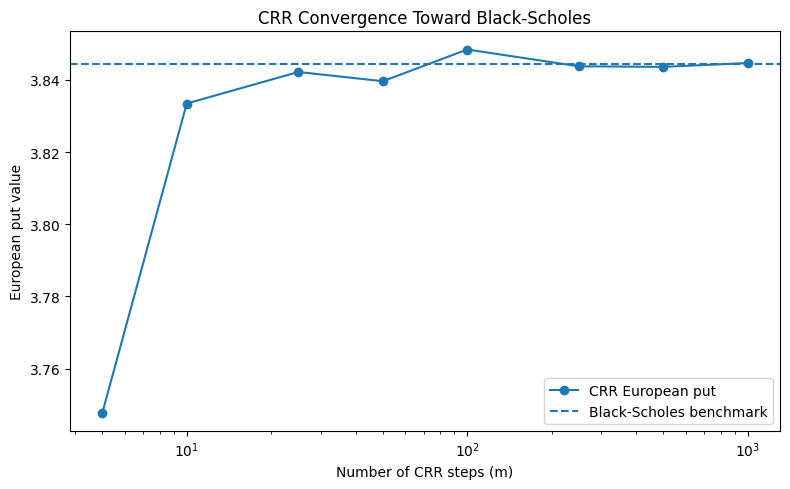

In [7]:
plt.figure(
    figsize=(8, 5)
)

plt.plot(
    convergence_table["m"],
    convergence_table["CRR European"],
    marker="o",
    label="CRR European put",
)

plt.axhline(
    bs_european,
    linewidth=1.5,
    linestyle="--",
    label="Black-Scholes benchmark",
)

plt.xscale("log")

plt.xlabel(
    "Number of CRR steps (m)"
)

plt.ylabel(
    "European put value"
)

plt.title(
    "CRR Convergence Toward Black-Scholes"
)

plt.legend()

plt.tight_layout()
plt.show()

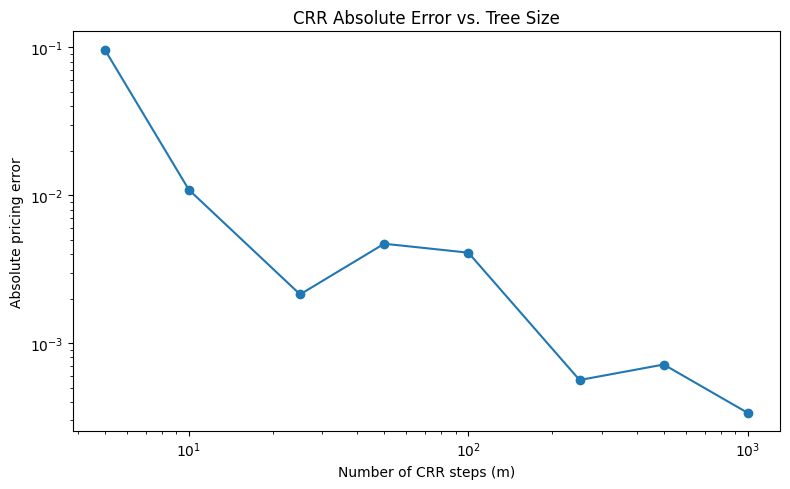

In [8]:
plt.figure(
    figsize=(8, 5)
)

plt.plot(
    convergence_table["m"],
    convergence_table["Absolute Error"],
    marker="o",
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(
    "Number of CRR steps (m)"
)

plt.ylabel(
    "Absolute pricing error"
)

plt.title(
    "CRR Absolute Error vs. Tree Size"
)

plt.tight_layout()
plt.show()

## 7. European Put Pricing by Dynamic Monte Carlo

The second pricing method simulates complete geometric Brownian motion paths under the risk-neutral measure.

The stock evolves according to

$$
S_{t+\Delta t}
=
S_t
\exp
\left[
\left(
r-\frac12\sigma^2
\right)\Delta t
+
\sigma\sqrt{\Delta t}Z
\right],
$$

where

$$
Z\sim N(0,1).
$$

The baseline simulation uses

$$
M=100
$$

time steps and

$$
I=50{,}000
$$

paths.

For a European put,

$$
h(S_T)=\max(K-S_T,0).
$$

Define the discounted payoff on simulated path $i$ as

$$
X_i=e^{-rT}h(S_T^{(i)}).
$$

The Monte Carlo estimator is

$$
\hat P_0
=
\frac{1}{I}
\sum_{i=1}^{I}X_i.
$$

Its estimated standard error is

$$
SE(\hat P_0)
=
\frac{s_X}{\sqrt I},
$$

where $s_X$ is the sample standard deviation of the discounted payoff observations.

An approximate 95% confidence interval is

$$
\hat P_0
\pm
z_{0.975}SE(\hat P_0).
$$

This interval measures finite-simulation sampling uncertainty. It does not measure model or parameter uncertainty.

In [9]:
M_mc = 100
I_mc = 50_000

t0_mc = time.perf_counter()

rng = default_rng(seed)

dt_mc = T / M_mc

Z = rng.standard_normal(
    (M_mc, I_mc)
)

S_mc = np.empty(
    (M_mc + 1, I_mc)
)

S_mc[0] = S0

for t in range(
    1,
    M_mc + 1,
):
    drift = (
        r
        - 0.5 * sigma ** 2
    ) * dt_mc

    diffusion = (
        sigma
        * math.sqrt(dt_mc)
        * Z[t - 1]
    )

    S_mc[t] = (
        S_mc[t - 1]
        * np.exp(
            drift + diffusion
        )
    )

ST_mc = S_mc[-1]

put_payoff_mc = np.maximum(
    K - ST_mc,
    0.0,
)

discounted_put_mc = (
    math.exp(-r * T)
    * put_payoff_mc
)

mc_european = float(
    discounted_put_mc.mean()
)

mc_payoff_sd = float(
    discounted_put_mc.std(
        ddof=1
    )
)

mc_se = (
    mc_payoff_sd
    / math.sqrt(I_mc)
)

z_95 = norm.ppf(
    0.975
)

mc_ci_low = (
    mc_european
    - z_95 * mc_se
)

mc_ci_high = (
    mc_european
    + z_95 * mc_se
)

mc_runtime = (
    time.perf_counter()
    - t0_mc
)

mc_abs_error = abs(
    mc_european
    - bs_european
)

bs_inside_mc_ci = (
    mc_ci_low
    <= bs_european
    <= mc_ci_high
)

print("MC time steps:", M_mc)
print("MC paths:", I_mc)
print("European put (MC):", mc_european)
print("European put (BS):", bs_european)
print("Monte Carlo SE:", mc_se)
print("95% CI lower:", mc_ci_low)
print("95% CI upper:", mc_ci_high)
print("Absolute MC error:", mc_abs_error)
print("BS benchmark inside CI:", bs_inside_mc_ci)
print("MC runtime (s):", mc_runtime)

MC time steps: 100
MC paths: 50000
European put (MC): 3.8157706053255445
European put (BS): 3.84430779159684
Monte Carlo SE: 0.01925106127668965
95% CI lower: 3.778039218559059
95% CI upper: 3.85350199209203
Absolute MC error: 0.028537186271295756
BS benchmark inside CI: True
MC runtime (s): 0.76640246199986


## 8. Reusable Dynamic Monte Carlo Engine

The dynamic Monte Carlo calculation is now packaged into a reusable function.

Unlike a terminal-state-only simulation, this function retains the complete stock-price path matrix

$$
S=
\left(S_t^{(i)}\right),
$$

because American option valuation requires information at intermediate exercise dates.

For the European put, the function returns:

- the full simulated path matrix;
- terminal stock prices;
- discounted put payoffs;
- Monte Carlo price;
- payoff standard deviation;
- standard error;
- 95% confidence interval;
- simulation runtime.

A fixed random seed makes the experiment reproducible and allows later pricing methods to use the same underlying simulated paths.

In [10]:
def dynamic_mc_put_pricer(
    S0,
    K,
    r,
    sigma,
    T,
    M=100,
    I=50_000,
    seed=100,
    confidence=0.95,
):
    """Simulate risk-neutral GBM paths and price a European put."""

    t0 = time.perf_counter()

    rng = default_rng(seed)

    dt = T / M

    Z = rng.standard_normal(
        (M, I)
    )

    S = np.empty(
        (M + 1, I)
    )

    S[0] = S0

    drift = (
        r
        - 0.5 * sigma ** 2
    ) * dt

    diffusion_scale = (
        sigma
        * math.sqrt(dt)
    )

    for t in range(
        1,
        M + 1,
    ):
        S[t] = (
            S[t - 1]
            * np.exp(
                drift
                + diffusion_scale
                * Z[t - 1]
            )
        )

    ST = S[-1]

    payoff = np.maximum(
        K - ST,
        0.0,
    )

    discounted_payoff = (
        math.exp(-r * T)
        * payoff
    )

    price = float(
        discounted_payoff.mean()
    )

    payoff_sd = float(
        discounted_payoff.std(
            ddof=1
        )
    )

    se = (
        payoff_sd
        / math.sqrt(I)
    )

    alpha = (
        1.0 - confidence
    )

    z = norm.ppf(
        1.0 - alpha / 2.0
    )

    ci_low = (
        price - z * se
    )

    ci_high = (
        price + z * se
    )

    runtime = (
        time.perf_counter()
        - t0
    )

    return {
        "M": M,
        "I": I,
        "dt": dt,
        "S": S,
        "ST": ST,
        "payoff": payoff,
        "discounted_payoff": discounted_payoff,
        "price": price,
        "payoff_sd": payoff_sd,
        "se": se,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "confidence": confidence,
        "runtime": runtime,
    }

In [11]:
baseline_mc = dynamic_mc_put_pricer(
    S0=S0,
    K=K,
    r=r,
    sigma=sigma,
    T=T,
    M=M_mc,
    I=I_mc,
    seed=seed,
)

print(
    "Function price:",
    baseline_mc["price"],
)

print(
    "Direct price:",
    mc_european,
)

print(
    "Price matches:",
    np.isclose(
        baseline_mc["price"],
        mc_european,
    ),
)

print(
    "SE matches:",
    np.isclose(
        baseline_mc["se"],
        mc_se,
    ),
)

print(
    "CI matches:",
    (
        np.isclose(
            baseline_mc["ci_low"],
            mc_ci_low,
        )
        and np.isclose(
            baseline_mc["ci_high"],
            mc_ci_high,
        )
    ),
)

print(
    "Paths match:",
    np.allclose(
        baseline_mc["S"],
        S_mc,
    ),
)

print(
    "Function runtime (s):",
    baseline_mc["runtime"],
)

Function price: 3.8157706053255445
Direct price: 3.8157706053255445
Price matches: True
SE matches: True
CI matches: True
Paths match: True
Function runtime (s): 0.6818930340000406


## 9. American Put Pricing with Least-Squares Monte Carlo

An American put can be exercised before maturity, including at the initial valuation date.

At an intermediate date, the holder compares the immediate exercise value

$$
h_t=\max(K-S_t,0)
$$

with the continuation value

$$
C_t
=
\mathbb E_Q
\left[
e^{-r\Delta t}V_{t+\Delta t}
\mid S_t
\right].
$$

In Monte Carlo simulation, this conditional expectation is not known directly.

Least-Squares Monte Carlo approximates it by regression.

For the in-the-money paths, the regression uses

$$
x=S_t
$$

and

$$
y=e^{-r\Delta t}V_{t+\Delta t}.
$$

A degree-five polynomial is used as a basis approximation:

$$
\widehat C_t(S_t)
=
\beta_0
+\beta_1S_t
+\beta_2S_t^2
+\cdots
+\beta_5S_t^5.
$$

At each simulated exercise date after time zero, exercise occurs when

$$
h_t>\widehat C_t(S_t).
$$

Otherwise, the option remains alive and its future value is discounted one step backward.

After backward induction reaches the first simulated date, the remaining continuation value is discounted to time zero and compared with the immediate time-zero exercise value

$$
h_0=\max(K-S_0,0).
$$

Therefore the final American value is

$$
V_0^{Am}
=
\max
\left(
h_0,
C_0
\right).
$$

This final comparison is necessary because an American option may be exercised immediately if intrinsic value exceeds the value of continuing.

The LSM calculation uses the exact same simulated stock-price paths as the European Monte Carlo calculation so that the comparison is based on a common simulated economy.

In [12]:
S_lsm = baseline_mc["S"]

M_lsm = S_lsm.shape[0] - 1
I_lsm = S_lsm.shape[1]

dt_lsm = T / M_lsm
df_lsm = math.exp(-r * dt_lsm)

degree_lsm = 5

# Retain the fitted continuation functions for diagnostics.
lsm_regressions = {}
lsm_regression_ranges = {}

t0_lsm = time.perf_counter()

# Intrinsic put value at every time and on every path
h_lsm = np.maximum(
    K - S_lsm,
    0.0,
)

# Start at maturity
V_lsm = h_lsm[-1].copy()

# Records local exercise decisions after time zero
exercise_lsm = np.zeros_like(
    h_lsm,
    dtype=bool,
)

exercise_lsm[-1] = (
    h_lsm[-1] > 0.0
)

# Backward induction from the last pre-maturity
# exercise date down to the first simulated date.
for t in range(M_lsm - 1, 0, -1):
    itm = h_lsm[t] > 0.0
    x = S_lsm[t, itm]
    y = df_lsm * V_lsm[itm]

    # Skip fitting when there are too few in-the-money observations.
    if x.size < degree_lsm + 1:
        V_lsm = df_lsm * V_lsm
        continue

    # Create the fitted polynomial before using or storing it.
    regression = np.polyfit(x, y, deg=degree_lsm)

    lsm_regressions[t] = regression.copy()
    lsm_regression_ranges[t] = (float(x.min()), float(x.max()))

    continuation = np.polyval(regression, S_lsm[t])

    exercise_now = itm & (h_lsm[t] > continuation)

    V_lsm = np.where(
        exercise_now,
        h_lsm[t],
        df_lsm * V_lsm,
    )

    exercise_lsm[t] = exercise_now

# Continuation value at time zero:
# discount the estimated values at the first
# simulated exercise date back one final step.
continuation_0_lsm = (
    df_lsm
    * float(
        V_lsm.mean()
    )
)

# Immediate exercise value at time zero
intrinsic_0_lsm = max(
    K - S0,
    0.0,
)

# American holder chooses the more valuable action.
exercise_at_0_lsm = (
    intrinsic_0_lsm
    > continuation_0_lsm
)

lsm_american = max(
    intrinsic_0_lsm,
    continuation_0_lsm,
)

lsm_runtime = (
    time.perf_counter()
    - t0_lsm
)

lsm_crr_abs_diff = abs(
    lsm_american
    - crr_american
)

lsm_crr_rel_diff = (
    lsm_crr_abs_diff
    / crr_american
)

lsm_premium_vs_mc_european = (
    lsm_american
    - mc_european
)

print(
    "American put (LSM):",
    lsm_american,
)

print(
    "American put (CRR):",
    crr_american,
)

print(
    "Absolute LSM-CRR difference:",
    lsm_crr_abs_diff,
)

print(
    "Relative LSM-CRR difference:",
    lsm_crr_rel_diff,
)

print(
    "LSM premium vs MC European:",
    lsm_premium_vs_mc_european,
)

print(
    "Time-0 intrinsic value:",
    intrinsic_0_lsm,
)

print(
    "Time-0 continuation value:",
    continuation_0_lsm,
)

print(
    "Exercise immediately at t=0:",
    exercise_at_0_lsm,
)

print(
    "LSM runtime (s):",
    lsm_runtime,
)
print("Stored continuation regressions:", len(lsm_regressions))
print("Stored regression ranges:", len(lsm_regression_ranges))

American put (LSM): 4.486772732139377
American put (CRR): 4.48637477750599
Absolute LSM-CRR difference: 0.00039795463338698767
Relative LSM-CRR difference: 8.87029401516504e-05
LSM premium vs MC European: 0.6710021268138324
Time-0 intrinsic value: 4.0
Time-0 continuation value: 4.486772732139377
Exercise immediately at t=0: False
LSM runtime (s): 3.8263433659999464
Stored continuation regressions: 99
Stored regression ranges: 99


Dates with fitted exercise threshold: 99
Threshold minimum: 29.551808692709614
Threshold maximum: 38.135409962172865


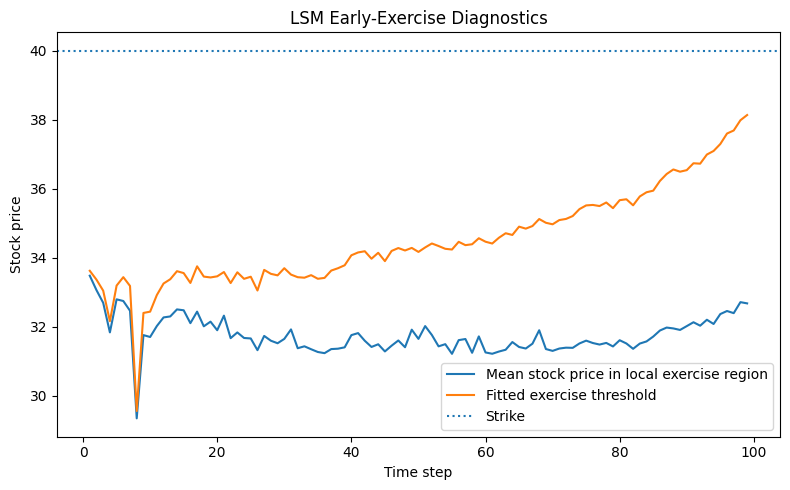

In [13]:
exercise_boundary = np.full(
    M_lsm + 1,
    np.nan,
)

exercise_counts = np.zeros(
    M_lsm + 1,
    dtype=int,
)

# Existing diagnostic:
# mean stock price across paths where the local
# LSM rule selects exercise.
for t in range(
    1,
    M_lsm,
):
    mask = exercise_lsm[t]

    exercise_counts[t] = (
        mask.sum()
    )

    if mask.any():
        exercise_boundary[t] = float(
            S_lsm[t, mask].mean()
        )

# -------------------------------------------------
# Fitted early-exercise threshold
# -------------------------------------------------

# At each date, estimate the stock-price threshold where
# immediate exercise value equals fitted continuation value:
#
#     K - S = C_hat_t(S)
#
# The search is restricted to the observed in-the-money
# stock-price range used for that date's regression.

exercise_threshold = np.full(
    M_lsm + 1,
    np.nan,
)

threshold_grid_size = 2000

for t in sorted(lsm_regressions):

    regression = lsm_regressions[t]

    x_min, x_max = (
        lsm_regression_ranges[t]
    )

    grid_low = max(
        x_min,
        1e-12,
    )

    grid_high = min(
        x_max,
        K,
    )

    if grid_low >= grid_high:
        continue

    stock_grid = np.linspace(
        grid_low,
        grid_high,
        threshold_grid_size,
    )

    intrinsic_grid = (
        K - stock_grid
    )

    continuation_grid = np.polyval(
        regression,
        stock_grid,
    )

    exercise_gap = (
        intrinsic_grid
        - continuation_grid
    )

    # For a put, the economically relevant threshold
    # is the highest crossing from exercise to continuation
    # as the stock price increases.
    crossing_index = np.where(
        (exercise_gap[:-1] >= 0.0)
        & (exercise_gap[1:] < 0.0)
    )[0]

    if crossing_index.size == 0:
        continue

    j = int(
        crossing_index[-1]
    )

    s_left = stock_grid[j]
    s_right = stock_grid[j + 1]

    g_left = exercise_gap[j]
    g_right = exercise_gap[j + 1]

    # Linear interpolation between the two grid points
    # surrounding the crossing.
    if np.isclose(
        g_right,
        g_left,
    ):
        threshold = (
            0.5
            * (
                s_left
                + s_right
            )
        )
    else:
        threshold = (
            s_left
            - g_left
            * (
                s_right
                - s_left
            )
            / (
                g_right
                - g_left
            )
        )

    exercise_threshold[t] = float(
        threshold
    )

finite_thresholds = np.isfinite(
    exercise_threshold
)

print(
    "Dates with fitted exercise threshold:",
    int(
        finite_thresholds.sum()
    ),
)

print(
    "Threshold minimum:",
    float(
        np.nanmin(
            exercise_threshold
        )
    ),
)

print(
    "Threshold maximum:",
    float(
        np.nanmax(
            exercise_threshold
        )
    ),
)

# -------------------------------------------------
# Plot both diagnostics
# -------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    exercise_boundary,
    label="Mean stock price in local exercise region",
)

plt.plot(
    exercise_threshold,
    label="Fitted exercise threshold",
)

plt.axhline(
    K,
    linestyle=":",
    linewidth=1.5,
    label="Strike",
)

plt.xlabel(
    "Time step"
)

plt.ylabel(
    "Stock price"
)

plt.title(
    "LSM Early-Exercise Diagnostics"
)

plt.legend()

plt.tight_layout()
plt.show()

## 10. Reusable LSM American-Put Engine

The direct Least-Squares Monte Carlo calculation is now packaged into a reusable function.

The function takes a simulated stock-price path matrix and applies backward induction with regression-estimated continuation values.

At each exercise date:

1. identify in-the-money put paths;
2. regress discounted future option values on current stock prices;
3. estimate continuation values;
4. exercise when intrinsic value exceeds estimated continuation value.

The function returns:

- the American put price;
- the exercise-decision matrix;
- the mean stock price in the local exercise region;
- a fitted early-exercise threshold;
- exercise counts by date;
- the time-zero intrinsic and continuation values;
- the time-zero exercise decision;
- the polynomial degree;
- runtime.

Two exercise diagnostics are kept distinct.

The **exercise-region mean** is the average stock price among simulated paths on which the local LSM rule selects exercise.

The **fitted exercise threshold** estimates the stock price satisfying

$$
K-S=\widehat C_t(S),
$$

where immediate exercise value equals the fitted continuation value.

The threshold is obtained numerically from the fitted continuation-value regression. It is therefore an estimated, model-dependent exercise boundary rather than an exact analytical free boundary.

In [14]:
def lsm_american_put(
    S,
    K,
    r,
    T,
    degree=5,
    threshold_grid_size=2000,
):
    """Price an American put using Least-Squares Monte Carlo."""

    t0 = time.perf_counter()

    M = S.shape[0] - 1
    I = S.shape[1]

    dt = T / M
    df = math.exp(-r * dt)

    # Intrinsic put values at every date and path
    h = np.maximum(
        K - S,
        0.0,
    )

    # Start from the terminal payoff
    V = h[-1].copy()

    # Record local exercise decisions
    exercise = np.zeros_like(
        h,
        dtype=bool,
    )

    exercise[-1] = (
        h[-1] > 0.0
    )

    # Store continuation-value regressions
    regressions = {}
    regression_ranges = {}

    # -------------------------------------------------
    # Backward induction
    # -------------------------------------------------

    for t in range(
        M - 1,
        0,
        -1,
    ):

        itm = (
            h[t] > 0.0
        )

        x = S[t, itm]

        y = (
            df
            * V[itm]
        )

        # Degree-d polynomial requires at least
        # d + 1 observations.
        if x.size < degree + 1:
            V = (
                df
                * V
            )
            continue

        regression = np.polyfit(
            x,
            y,
            deg=degree,
        )

        regressions[t] = (
            regression.copy()
        )

        regression_ranges[t] = (
            float(x.min()),
            float(x.max()),
        )

        continuation = np.polyval(
            regression,
            S[t],
        )

        exercise_now = (
            itm
            & (
                h[t]
                > continuation
            )
        )

        V = np.where(
            exercise_now,
            h[t],
            df * V,
        )

        exercise[t] = (
            exercise_now
        )

    # -------------------------------------------------
    # Time-zero American exercise decision
    # -------------------------------------------------

    continuation_0 = (
        df
        * float(
            V.mean()
        )
    )

    S0_path = float(
        S[0, 0]
    )

    intrinsic_0 = max(
        K - S0_path,
        0.0,
    )

    exercise_at_0 = (
        intrinsic_0
        > continuation_0
    )

    price = max(
        intrinsic_0,
        continuation_0,
    )

    # -------------------------------------------------
    # Exercise-region mean
    # -------------------------------------------------

    exercise_region_mean = np.full(
        M + 1,
        np.nan,
    )

    exercise_counts = np.zeros(
        M + 1,
        dtype=int,
    )

    for t in range(
        1,
        M,
    ):
        mask = exercise[t]

        exercise_counts[t] = (
            mask.sum()
        )

        if mask.any():
            exercise_region_mean[t] = float(
                S[t, mask].mean()
            )

    # -------------------------------------------------
    # Fitted early-exercise threshold
    # -------------------------------------------------

    exercise_threshold = np.full(
        M + 1,
        np.nan,
    )

    for t in sorted(
        regressions
    ):

        regression = (
            regressions[t]
        )

        x_min, x_max = (
            regression_ranges[t]
        )

        grid_low = max(
            x_min,
            1e-12,
        )

        grid_high = min(
            x_max,
            K,
        )

        if grid_low >= grid_high:
            continue

        stock_grid = np.linspace(
            grid_low,
            grid_high,
            threshold_grid_size,
        )

        intrinsic_grid = np.maximum(
            K - stock_grid,
            0.0,
        )

        continuation_grid = np.polyval(
            regression,
            stock_grid,
        )

        exercise_gap = (
            intrinsic_grid
            - continuation_grid
        )

        # For a put, use the highest crossing from
        # exercise to continuation as S increases.
        crossing_index = np.where(
            (
                exercise_gap[:-1]
                >= 0.0
            )
            & (
                exercise_gap[1:]
                < 0.0
            )
        )[0]

        if crossing_index.size == 0:
            continue

        j = int(
            crossing_index[-1]
        )

        s_left = (
            stock_grid[j]
        )

        s_right = (
            stock_grid[j + 1]
        )

        g_left = (
            exercise_gap[j]
        )

        g_right = (
            exercise_gap[j + 1]
        )

        # Linear interpolation between the
        # grid points surrounding the crossing.
        if np.isclose(
            g_right,
            g_left,
        ):
            threshold = (
                0.5
                * (
                    s_left
                    + s_right
                )
            )
        else:
            threshold = (
                s_left
                - g_left
                * (
                    s_right
                    - s_left
                )
                / (
                    g_right
                    - g_left
                )
            )

        exercise_threshold[t] = float(
            threshold
        )

    runtime = (
        time.perf_counter()
        - t0
    )

    return {
        "price": price,
        "M": M,
        "I": I,
        "dt": dt,
        "degree": degree,
        "exercise": exercise,
        "exercise_region_mean": exercise_region_mean,
        "exercise_threshold": exercise_threshold,
        "exercise_counts": exercise_counts,
        "intrinsic_0": intrinsic_0,
        "continuation_0": continuation_0,
        "exercise_at_0": exercise_at_0,
        "runtime": runtime,
    }

In [15]:
baseline_lsm = lsm_american_put(
    S=baseline_mc["S"],
    K=K,
    r=r,
    T=T,
    degree=degree_lsm,
)

print(
    "Function LSM price:",
    baseline_lsm["price"],
)

print(
    "Direct LSM price:",
    lsm_american,
)

print(
    "Price matches:",
    np.isclose(
        baseline_lsm["price"],
        lsm_american,
    ),
)

print(
    "Exercise decisions match:",
    np.array_equal(
        baseline_lsm["exercise"],
        exercise_lsm,
    ),
)

print(
    "Exercise-region mean matches:",
    np.allclose(
        baseline_lsm[
            "exercise_region_mean"
        ],
        exercise_boundary,
        equal_nan=True,
    ),
)

print(
    "Exercise threshold matches:",
    np.allclose(
        baseline_lsm[
            "exercise_threshold"
        ],
        exercise_threshold,
        equal_nan=True,
    ),
)

print(
    "Time-0 intrinsic matches:",
    np.isclose(
        baseline_lsm["intrinsic_0"],
        intrinsic_0_lsm,
    ),
)

print(
    "Time-0 continuation matches:",
    np.isclose(
        baseline_lsm["continuation_0"],
        continuation_0_lsm,
    ),
)

print(
    "Time-0 exercise decision matches:",
    (
        baseline_lsm[
            "exercise_at_0"
        ]
        == exercise_at_0_lsm
    ),
)

print(
    "American value >= intrinsic value:",
    (
        baseline_lsm["price"]
        >= baseline_lsm[
            "intrinsic_0"
        ]
    ),
)

print(
    "Dates with fitted exercise threshold:",
    int(
        np.isfinite(
            baseline_lsm[
                "exercise_threshold"
            ]
        ).sum()
    ),
)

print(
    "Function runtime (s):",
    baseline_lsm["runtime"],
)

Function LSM price: 4.486772732139377
Direct LSM price: 4.486772732139377
Price matches: True
Exercise decisions match: True
Exercise-region mean matches: True
Exercise threshold matches: True
Time-0 intrinsic matches: True
Time-0 continuation matches: True
Time-0 exercise decision matches: True
American value >= intrinsic value: True
Dates with fitted exercise threshold: 99
Function runtime (s): 2.624992433999978


## 11. Pricing Accuracy and Runtime Leaderboard

The final model comparison evaluates several contract parameter sets.

The official capstone requires a comparison of accuracy and runtime but does not prescribe the exact scenarios. This implementation uses:

| Scenario | $S_0$ | $K$ | $\sigma$ |
|---|---:|---:|---:|
| Baseline | 36 | 40 | 20% |
| Higher volatility | 36 | 40 | 30% |
| Lower spot | 32 | 40 | 20% |

The risk-free rate and maturity remain

$$
r=6\%,
\qquad
T=1.
$$

For European puts, accuracy is measured relative to the analytical Black–Scholes value.

For American puts, a 2,000-step CRR calculation is used as a high-resolution numerical reference:

$$
V_0^{Am,\text{ref}}
=
V_0^{CRR}(m=2000).
$$

This reference is numerical rather than exact.

The production CRR calculation uses

$$
m=500,
$$

while Monte Carlo and LSM use

$$
M=100
$$

time steps and

$$
I=50{,}000
$$

paths.

The same random seed is used in every Monte Carlo scenario, producing common random numbers and making scenario comparisons less sensitive to unrelated sampling variation.

For LSM, total runtime includes both path simulation and the subsequent regression-based backward-induction calculation.

In [16]:
def bs_put_price(
    S0,
    K,
    r,
    sigma,
    T,
):
    """Analytical Black-Scholes European put value."""

    d1 = (
        math.log(S0 / K)
        + (
            r
            + 0.5 * sigma ** 2
        ) * T
    ) / (
        sigma
        * math.sqrt(T)
    )

    d2 = (
        d1
        - sigma * math.sqrt(T)
    )

    return float(
        K
        * math.exp(-r * T)
        * norm.cdf(-d2)
        - S0
        * norm.cdf(-d1)
    )

In [17]:
bakeoff_scenarios = [
    {
        "Scenario": "Baseline",
        "S0": 36.0,
        "K": 40.0,
        "r": 0.06,
        "sigma": 0.20,
        "T": 1.0,
    },
    {
        "Scenario": "Higher volatility",
        "S0": 36.0,
        "K": 40.0,
        "r": 0.06,
        "sigma": 0.30,
        "T": 1.0,
    },
    {
        "Scenario": "Lower spot",
        "S0": 32.0,
        "K": 40.0,
        "r": 0.06,
        "sigma": 0.20,
        "T": 1.0,
    },
]

m_bakeoff = 500
m_reference = 2000

M_bakeoff = 100
I_bakeoff = 50_000

leaderboard_rows = []

for scenario in bakeoff_scenarios:

    s0_value = scenario["S0"]
    k_value = scenario["K"]
    r_value = scenario["r"]
    sigma_value = scenario["sigma"]
    t_value = scenario["T"]

    # Analytical European benchmark
    bs_value = bs_put_price(
        S0=s0_value,
        K=k_value,
        r=r_value,
        sigma=sigma_value,
        T=t_value,
    )

    # High-resolution numerical American reference
    crr_reference = crr_put_pricer(
        S0=s0_value,
        K=k_value,
        r=r_value,
        sigma=sigma_value,
        T=t_value,
        m=m_reference,
    )

    # Production CRR calculation
    crr_result = crr_put_pricer(
        S0=s0_value,
        K=k_value,
        r=r_value,
        sigma=sigma_value,
        T=t_value,
        m=m_bakeoff,
    )

    # Dynamic Monte Carlo
    mc_result = dynamic_mc_put_pricer(
        S0=s0_value,
        K=k_value,
        r=r_value,
        sigma=sigma_value,
        T=t_value,
        M=M_bakeoff,
        I=I_bakeoff,
        seed=seed,
    )

    # LSM on the exact same simulated paths
    lsm_result = lsm_american_put(
        S=mc_result["S"],
        K=k_value,
        r=r_value,
        T=t_value,
        degree=5,
    )

    leaderboard_rows.append(
        {
            "Scenario": scenario["Scenario"],
            "S0": s0_value,
            "Sigma": sigma_value,
            "BS European": bs_value,
            "CRR European": crr_result["european"],
            "CRR Eur Error": abs(
                crr_result["european"]
                - bs_value
            ),
            "MC European": mc_result["price"],
            "MC SE": mc_result["se"],
            "MC Eur Error": abs(
                mc_result["price"]
                - bs_value
            ),
            "American Reference": crr_reference["american"],
            "CRR American": crr_result["american"],
            "CRR Am Error": abs(
                crr_result["american"]
                - crr_reference["american"]
            ),
            "LSM American": lsm_result["price"],
            "LSM Am Error": abs(
                lsm_result["price"]
                - crr_reference["american"]
            ),
            "CRR Runtime (s)": crr_result["runtime"],
            "MC Runtime (s)": mc_result["runtime"],
            "LSM Total Runtime (s)": (
                mc_result["runtime"]
                + lsm_result["runtime"]
            ),
        }
    )

leaderboard_table = pd.DataFrame(
    leaderboard_rows
)

leaderboard_table

,Scenario,S0,Sigma,BS European,CRR European,CRR Eur Error,MC European,MC SE,MC Eur Error,American Reference,CRR American,CRR Am Error,LSM American,LSM Am Error,CRR Runtime (s),MC Runtime (s),LSM Total Runtime (s)
0,Baseline,36.0,0.2,3.844308,3.843591,0.000717,3.815771,0.019251,0.028537,4.486687,4.486375,0.000312,4.486773,0.000086,0.037308,0.410559,3.482599
1,Higher volatility,36.0,0.3,5.277086,5.275817,0.001269,5.237794,0.026270,0.039291,5.738051,5.737570,0.000480,5.736286,0.001765,0.089923,0.337565,4.726308
2,Lower spot,32.0,0.2,6.480012,6.480270,0.000258,6.455416,0.022415,0.024596,8.000000,8.000000,0.000000,8.000000,0.000000,0.019512,0.161692,1.673136


### Leaderboard Interpretation

The pricing bake-off illustrates a trade-off between numerical structure, accuracy, and computational cost.

For the European put, the 500-step CRR tree tracks the analytical Black–Scholes benchmark extremely closely across all three scenarios. Monte Carlo produces somewhat larger pricing errors because its estimates contain finite-sample simulation noise, summarized by the Monte Carlo standard error.

For the American put, both CRR and LSM remain close to the high-resolution 2,000-step CRR numerical reference.

The lower-spot scenario provides an important boundary case. With

$$
S_0=32
\qquad\text{and}\qquad
K=40,
$$

immediate exercise has value

$$
K-S_0=8.
$$

Both the CRR and corrected LSM methods therefore return

$$
V_0^{Am}=8.
$$

This confirms the American pricing logic

$$
V_0^{Am}
=
\max
\left(
\text{intrinsic value},
\text{continuation value}
\right)
$$

even at the initial valuation date.

Runtime results show a clear computational hierarchy in this experiment. CRR is substantially faster than path-based Monte Carlo, while LSM is the most computationally demanding because it combines path simulation with repeated continuation-value regressions.

Absolute runtime depends on the execution environment, so the timings should be interpreted as empirical comparisons within this notebook rather than universal performance constants.

In [18]:
leaderboard_display = leaderboard_table[
    [
        "Scenario",
        "CRR Eur Error",
        "MC Eur Error",
        "MC SE",
        "CRR Am Error",
        "LSM Am Error",
        "CRR Runtime (s)",
        "MC Runtime (s)",
        "LSM Total Runtime (s)",
    ]
].copy()

numeric_columns = [
    "CRR Eur Error",
    "MC Eur Error",
    "MC SE",
    "CRR Am Error",
    "LSM Am Error",
    "CRR Runtime (s)",
    "MC Runtime (s)",
    "LSM Total Runtime (s)",
]

for column in numeric_columns:
    leaderboard_display[column] = (
        leaderboard_display[column]
        .map(lambda x: f"{x:.6f}")
    )

leaderboard_display

,Scenario,CRR Eur Error,MC Eur Error,MC SE,CRR Am Error,LSM Am Error,CRR Runtime (s),MC Runtime (s),LSM Total Runtime (s)
0,Baseline,0.000717,0.028537,0.019251,0.000312,0.000086,0.037308,0.410559,3.482599
1,Higher volatility,0.001269,0.039291,0.026270,0.000480,0.001765,0.089923,0.337565,4.726308
2,Lower spot,0.000258,0.024596,0.022415,0.000000,0.000000,0.019512,0.161692,1.673136


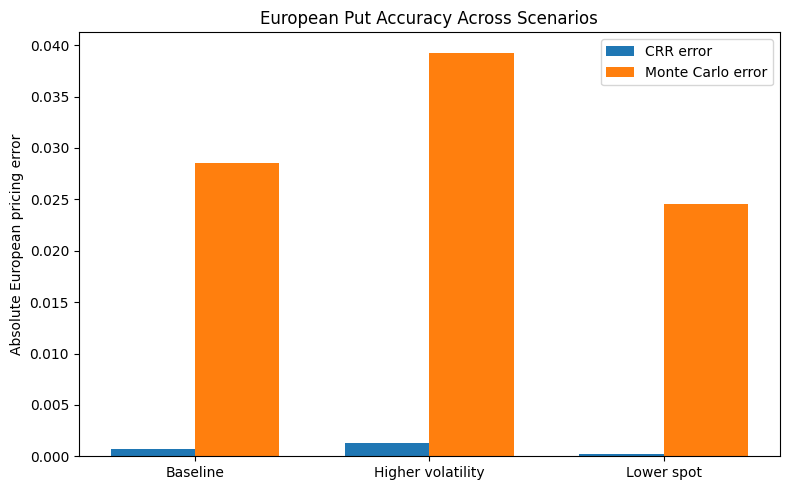

In [19]:
x = np.arange(
    len(leaderboard_table)
)

width = 0.36

plt.figure(
    figsize=(8, 5)
)

plt.bar(
    x - width / 2,
    leaderboard_table["CRR Eur Error"],
    width=width,
    label="CRR error",
)

plt.bar(
    x + width / 2,
    leaderboard_table["MC Eur Error"],
    width=width,
    label="Monte Carlo error",
)

plt.xticks(
    x,
    leaderboard_table["Scenario"],
)

plt.ylabel(
    "Absolute European pricing error"
)

plt.title(
    "European Put Accuracy Across Scenarios"
)

plt.legend()

plt.tight_layout()
plt.show()

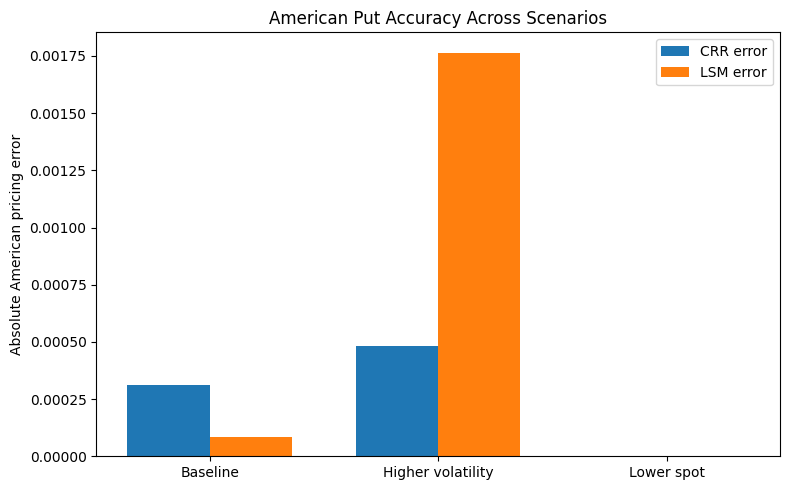

In [20]:
plt.figure(
    figsize=(8, 5)
)

plt.bar(
    x - width / 2,
    leaderboard_table["CRR Am Error"],
    width=width,
    label="CRR error",
)

plt.bar(
    x + width / 2,
    leaderboard_table["LSM Am Error"],
    width=width,
    label="LSM error",
)

plt.xticks(
    x,
    leaderboard_table["Scenario"],
)

plt.ylabel(
    "Absolute American pricing error"
)

plt.title(
    "American Put Accuracy Across Scenarios"
)

plt.legend()

plt.tight_layout()
plt.show()

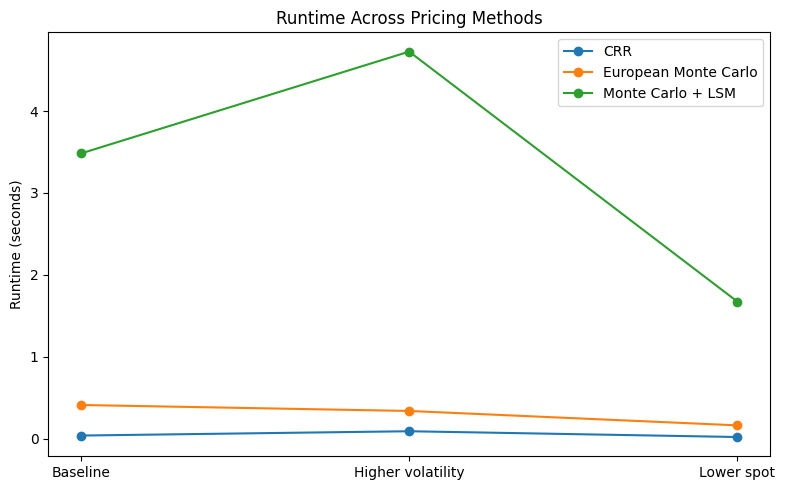

In [21]:
plt.figure(
    figsize=(8, 5)
)

plt.plot(
    leaderboard_table["Scenario"],
    leaderboard_table["CRR Runtime (s)"],
    marker="o",
    label="CRR",
)

plt.plot(
    leaderboard_table["Scenario"],
    leaderboard_table["MC Runtime (s)"],
    marker="o",
    label="European Monte Carlo",
)

plt.plot(
    leaderboard_table["Scenario"],
    leaderboard_table["LSM Total Runtime (s)"],
    marker="o",
    label="Monte Carlo + LSM",
)

plt.ylabel(
    "Runtime (seconds)"
)

plt.title(
    "Runtime Across Pricing Methods"
)

plt.legend()

plt.tight_layout()
plt.show()

## 12. Conclusions and Model Limitations

### Conclusions

This capstone compared numerical approaches for pricing European and American put options in a dynamic economy.

The baseline contract used

$$
S_0=36,
\qquad
K=40,
\qquad
r=6\%,
\qquad
\sigma=20\%,
\qquad
T=1.
$$

### CRR Binomial Pricing

A 500-step Cox–Ross–Rubinstein tree produced the baseline European put value

$$
\boxed{
P_0^{CRR}\approx3.84359
}
$$

and the American put value

$$
\boxed{
V_0^{CRR}\approx4.48637.
}
$$

The analytical Black–Scholes European benchmark was

$$
\boxed{
P_0^{BS}\approx3.84431.
}
$$

The corresponding CRR European absolute error was approximately

$$
0.00072.
$$

The convergence experiment showed that CRR pricing error generally decreases as the number of time steps increases, although convergence is not monotonic at every individual tree size.

This reflects the approximation

$$
m\uparrow
\quad\Rightarrow\quad
\Delta t=\frac{T}{m}\downarrow
\quad\Rightarrow\quad
P_0^{CRR}\rightarrow P_0^{BS}.
$$

### European Monte Carlo Pricing

Using

$$
M=100
$$

time steps and

$$
I=50{,}000
$$

simulated paths, the baseline European Monte Carlo estimate was approximately

$$
\boxed{
P_0^{MC}\approx3.81577.
}
$$

The Monte Carlo standard error was approximately

$$
0.01925,
$$

giving an approximate 95% confidence interval of

$$
[3.77804,\;3.85350].
$$

The analytical Black–Scholes value lies inside this interval.

For this simulation run, the observed difference between the Monte Carlo estimate and the analytical value is consistent with finite-sample sampling variation.

The confidence interval measures Monte Carlo sampling uncertainty under the model. It does not measure model or parameter uncertainty.

### Least-Squares Monte Carlo

The baseline Least-Squares Monte Carlo estimate for the American put was

$$
\boxed{
V_0^{LSM}\approx4.48677.
}
$$

The corresponding 500-step CRR value was approximately

$$
4.48637.
$$

The two values differ by less than

$$
0.0004.
$$

LSM estimates continuation values by regression on in-the-money simulated paths and applies the American exercise rule

$$
V_t^{Am}
=
\max
\left(
h_t,
\widehat C_t
\right).
$$

The exercise diagnostics distinguish between two different quantities.

The **exercise-region mean** records the average stock price among simulated paths on which the local LSM rule selects exercise.

The **fitted exercise threshold** estimates the stock price at which

$$
K-S
=
\widehat C_t(S),
$$

so that immediate exercise and fitted continuation value are equal.

For an American put, stock prices below this threshold are associated with the exercise region, subject to the approximation produced by the fitted continuation-value regression.

The fitted threshold is an estimated numerical boundary. It is not an exact analytical free boundary and depends on the simulated paths, regression basis, polynomial degree, and discrete exercise grid.

### Time-Zero Exercise Check

The lower-spot scenario,

$$
S_0=32,
\qquad
K=40,
$$

provides an important American-option boundary case.

Immediate exercise at time zero has value

$$
K-S_0=8.
$$

The continuation value is not more valuable in that scenario, so the American price is

$$
\boxed{
V_0^{Am}=8.
}
$$

Both the LSM implementation and CRR calculation reproduce this value.

This illustrates the full American pricing rule:

$$
\boxed{
V_0^{Am}
=
\max
\left(
\text{time-zero intrinsic value},
\text{time-zero continuation value}
\right).
}
$$

### Pricing Bake-Off

Across the three scenarios, the 500-step CRR European prices were very close to their analytical Black–Scholes benchmarks.

The Monte Carlo European estimates contained finite-sample simulation error, summarized by their estimated standard errors.

For American pricing, both the 500-step CRR method and LSM remained close to the 2,000-step CRR numerical references.

The comparison did not produce a uniform ordering of American pricing error across every scenario.

The lower-spot scenario produced zero American pricing error relative to the numerical reference for both methods because immediate exercise was optimal and both methods returned the intrinsic value of 8.

### Runtime

The timing results compare computational cost within this notebook.

CRR, Monte Carlo, and LSM use different numerical operations and therefore produce different runtimes. LSM adds repeated continuation-value regressions to Monte Carlo path simulation, making it computationally more demanding in these experiments.

Exact timings depend on the execution environment, hardware, current runtime load, and implementation details. They should therefore be interpreted as experiment-specific diagnostics rather than universal performance constants.

### Model Limitations

The results should be interpreted within the assumptions and numerical design of this notebook.

In particular:

- stock prices follow risk-neutral geometric Brownian motion;
- the risk-free rate and volatility are constant;
- no dividends are modeled;
- transaction costs, bid-ask spreads, liquidity constraints, and market impact are ignored;
- CRR values depend on a finite time grid;
- Monte Carlo estimates contain finite-sample sampling error;
- LSM continuation values depend on the selected regression basis;
- the degree-five polynomial is an approximation rather than a structural financial law;
- exercise opportunities are restricted to the discrete simulation dates;
- the exercise-region mean is not itself an exercise boundary;
- the fitted exercise threshold is a numerical estimate rather than an exact analytical free boundary;
- the 2,000-step CRR American benchmark is a high-resolution numerical reference, not an analytical closed-form value;
- measured runtimes depend on the execution environment.

The notebook therefore demonstrates numerical pricing principles rather than an empirical trading strategy.

The central Chapter 6 workflow is

$$
\boxed{
\text{dynamic state evolution}
\rightarrow
\text{risk-neutral valuation}
\rightarrow
\text{backward induction}
\rightarrow
\text{Monte Carlo paths}
\rightarrow
\text{continuation-value regression}
\rightarrow
\text{early exercise}
\rightarrow
\text{accuracy/runtime diagnostics}.
}
$$

## 13. Reproducibility and Validation

The final validation block checks the main financial and computational relationships used throughout the capstone.

The tests verify that:

1. primitive market parameters are admissible;
2. the reusable CRR engine reproduces the direct baseline calculation;
3. the 500-step CRR European value is close to Black–Scholes;
4. CRR convergence improves materially between the smallest and largest tested trees;
5. the reusable Monte Carlo engine reproduces the direct calculation;
6. the baseline Black–Scholes value lies inside the Monte Carlo 95% confidence interval for this simulation;
7. the Monte Carlo standard error is positive;
8. the reusable LSM engine reproduces the direct LSM price;
9. the reusable LSM exercise decisions reproduce the direct implementation;
10. the exercise-region mean reproduces the direct diagnostic;
11. the fitted exercise threshold reproduces the direct threshold calculation;
12. the American value is never below immediate intrinsic value;
13. the time-zero LSM decision is internally consistent;
14. all leaderboard Monte Carlo standard errors are positive;
15. the three Black–Scholes European benchmarks lie inside their corresponding approximate Monte Carlo 95% intervals for the fixed-seed simulations;
16. all measured runtimes are positive;
17. the lower-spot American case correctly recognizes immediate exercise;
18. the leaderboard contains the intended three scenarios.

These checks establish internal consistency and reproducibility of the implemented calculations. They do not constitute a proof that the numerical model is free of all approximation or specification error.

In [22]:
checks = {}

# -------------------------------------------------
# Primitive market inputs
# -------------------------------------------------

checks["positive_spot"] = (
    S0 > 0
)

checks["positive_strike"] = (
    K > 0
)

checks["positive_volatility"] = (
    sigma > 0
)

checks["positive_maturity"] = (
    T > 0
)

# -------------------------------------------------
# CRR baseline consistency
# -------------------------------------------------

checks["crr_european_matches_direct"] = np.isclose(
    baseline_crr["european"],
    crr_european,
)

checks["crr_american_matches_direct"] = np.isclose(
    baseline_crr["american"],
    crr_american,
)

checks["crr_q_matches_direct"] = np.isclose(
    baseline_crr["q"],
    q_crr,
)

checks["crr_close_to_black_scholes"] = (
    abs(
        baseline_crr["european"]
        - bs_european
    )
    < 0.001
)

# -------------------------------------------------
# CRR convergence
# -------------------------------------------------

first_crr_error = float(
    convergence_table.iloc[0][
        "Absolute Error"
    ]
)

last_crr_error = float(
    convergence_table.iloc[-1][
        "Absolute Error"
    ]
)

checks["crr_convergence_improves"] = (
    last_crr_error
    < first_crr_error
)

# -------------------------------------------------
# Monte Carlo baseline consistency
# -------------------------------------------------

checks["mc_price_matches_direct"] = np.isclose(
    baseline_mc["price"],
    mc_european,
)

checks["mc_se_matches_direct"] = np.isclose(
    baseline_mc["se"],
    mc_se,
)

checks["mc_ci_matches_direct"] = (
    np.isclose(
        baseline_mc["ci_low"],
        mc_ci_low,
    )
    and np.isclose(
        baseline_mc["ci_high"],
        mc_ci_high,
    )
)

checks["baseline_bs_inside_mc_ci"] = (
    baseline_mc["ci_low"]
    <= bs_european
    <= baseline_mc["ci_high"]
)

checks["positive_mc_se"] = (
    baseline_mc["se"] > 0
)

# -------------------------------------------------
# LSM baseline consistency
# -------------------------------------------------

checks["lsm_price_matches_direct"] = np.isclose(
    baseline_lsm["price"],
    lsm_american,
)

checks["lsm_exercise_matches_direct"] = np.array_equal(
    baseline_lsm["exercise"],
    exercise_lsm,
)

checks["lsm_exercise_region_mean_matches_direct"] = np.allclose(
    baseline_lsm[
        "exercise_region_mean"
    ],
    exercise_boundary,
    equal_nan=True,
)

checks["lsm_threshold_matches_direct"] = np.allclose(
    baseline_lsm[
        "exercise_threshold"
    ],
    exercise_threshold,
    equal_nan=True,
)

checks["lsm_value_at_least_intrinsic"] = (
    baseline_lsm["price"]
    >= baseline_lsm["intrinsic_0"]
)

checks["lsm_time0_decision_consistent"] = np.isclose(
    baseline_lsm["price"],
    max(
        baseline_lsm["intrinsic_0"],
        baseline_lsm["continuation_0"],
    ),
)

# -------------------------------------------------
# Leaderboard diagnostics
# -------------------------------------------------

checks["leaderboard_scenario_count"] = (
    len(leaderboard_table) == 3
)

checks["all_mc_se_positive"] = bool(
    (
        leaderboard_table["MC SE"]
        > 0
    ).all()
)

mc_ci_half_width = (
    norm.ppf(0.975)
    * leaderboard_table["MC SE"]
)

checks["all_bs_inside_mc_95_intervals"] = bool(
    (
        np.abs(
            leaderboard_table["MC European"]
            - leaderboard_table["BS European"]
        )
        <= mc_ci_half_width
    ).all()
)

checks["all_crr_runtimes_positive"] = bool(
    (
        leaderboard_table["CRR Runtime (s)"]
        > 0
    ).all()
)

checks["all_mc_runtimes_positive"] = bool(
    (
        leaderboard_table["MC Runtime (s)"]
        > 0
    ).all()
)

checks["all_lsm_runtimes_positive"] = bool(
    (
        leaderboard_table[
            "LSM Total Runtime (s)"
        ]
        > 0
    ).all()
)

# -------------------------------------------------
# Time-zero lower-spot boundary case
# -------------------------------------------------

lower_spot_row = (
    leaderboard_table[
        leaderboard_table["Scenario"]
        == "Lower spot"
    ]
    .iloc[0]
)

lower_spot_intrinsic = (
    K
    - lower_spot_row["S0"]
)

checks["lower_spot_crr_immediate_exercise"] = np.isclose(
    lower_spot_row["CRR American"],
    lower_spot_intrinsic,
)

checks["lower_spot_lsm_immediate_exercise"] = np.isclose(
    lower_spot_row["LSM American"],
    lower_spot_intrinsic,
)

checks["lower_spot_crr_error_zero"] = np.isclose(
    lower_spot_row["CRR Am Error"],
    0.0,
)

checks["lower_spot_lsm_error_zero"] = np.isclose(
    lower_spot_row["LSM Am Error"],
    0.0,
)

# -------------------------------------------------
# Display and enforce validation
# -------------------------------------------------

for name, passed in checks.items():
    print(
        f"{name}: {passed}"
    )

print()

print(
    "Validation checks passed:",
    sum(checks.values()),
    "/",
    len(checks),
)

assert all(
    checks.values()
)

print(
    "All validation checks passed."
)

positive_spot: True
positive_strike: True
positive_volatility: True
positive_maturity: True
crr_european_matches_direct: True
crr_american_matches_direct: True
crr_q_matches_direct: True
crr_close_to_black_scholes: True
crr_convergence_improves: True
mc_price_matches_direct: True
mc_se_matches_direct: True
mc_ci_matches_direct: True
baseline_bs_inside_mc_ci: True
positive_mc_se: True
lsm_price_matches_direct: True
lsm_exercise_matches_direct: True
lsm_exercise_region_mean_matches_direct: True
lsm_threshold_matches_direct: True
lsm_value_at_least_intrinsic: True
lsm_time0_decision_consistent: True
leaderboard_scenario_count: True
all_mc_se_positive: True
all_bs_inside_mc_95_intervals: True
all_crr_runtimes_positive: True
all_mc_runtimes_positive: True
all_lsm_runtimes_positive: True
lower_spot_crr_immediate_exercise: True
lower_spot_lsm_immediate_exercise: True
lower_spot_crr_error_zero: True
lower_spot_lsm_error_zero: True

Validation checks passed: 30 / 30
All validation checks passed